# Player Archetypes — simulation v2 training notebook

Model v1.0.0 (`models/archetype_model.json`) was trained on players whose features were drawn
**independently**, so the generator could make impossible players: a 60h game completed after 1 hour,
100% trophies on an unfinished game, "completing" Dota 2. Generator v2 (`archetype_sim_v2.py`) draws
**real catalogue games** and makes features depend on each other the way real play does. Every rule and
parameter is in `archetype_sim_v2.RULES` with its reason and source; none was tuned on the clusters.

This notebook: catalogue (§1) → rules (§2) → plausibility checks (§3) → train v2 with v1's pipeline and
pre-registered k rule (§4) → compare with v1 (§5) → sensitivity of each new rule (§6).

**Nothing here touches v1**: the model JSON, the served endpoint, the shared feature function and the k rule
are unchanged. v2 writes `models/archetype_model_v2.json` (version `2.0.0-candidate`), which is **not** wired
into the app. Clusters are not named here; names and temperature need review before any app change.

In [1]:
# --- Paths: edit these --------------------------------------------------------
REPO_URL  = "https://github.com/aljoharas/2026-GP1-Group8.git"
REPO_BRANCH = "feature/archetype-sim-v2"
USE_DRIVE = False                                   # True: read the CSVs from Google Drive
DRIVE_DIR = "/content/drive/MyDrive/loadout"         # holds steam-200k.csv and steam.csv
SEED = 42

import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO_DIR = Path("/content/2026-GP1-Group8")
    if not REPO_DIR.exists():
        !git clone -q -b {REPO_BRANCH} {REPO_URL} {REPO_DIR}
    if USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
else:
    REPO_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# data/ is gitignored: in Colab without Drive, upload both CSVs to these paths.
# steam.csv is the Kaggle "Steam Store Games (Clean dataset)" (nikdavis).
DATA_DIR = Path(DRIVE_DIR) if USE_DRIVE else REPO_DIR / "data"
STEAM_CSV = DATA_DIR / "steam-200k.csv"
STORE_CSV = DATA_DIR / "steam.csv"
CATALOGUE_CSV = REPO_DIR / "data" / "steam_catalogue.csv"
FIGURES = REPO_DIR / "notebooks" / "figures" / "v2"
RESULTS = REPO_DIR / "notebooks" / "sim_v2"
for d in (REPO_DIR / "data", FIGURES, RESULTS):
    d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(REPO_DIR / "notebooks"))
sys.path.insert(0, str(REPO_DIR / "backend" / "recommender"))
print("repo:", REPO_DIR, "| steam-200k:", STEAM_CSV.exists(), "| steam.csv:", STORE_CSV.exists())

repo: /Users/aljoharaalsultan/Development/2026-GP1-Group8 | steam-200k: True | steam.csv: True


In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

import archetype_v2_lib as L
from archetype_v2_lib import FN, sim, sim2, ac

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

# v1 notebook's chart style
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
MIXED = "#a3a29b"
DIVERGING = LinearSegmentedColormap.from_list("blue_red", ["#1c5cab", "#86b6ef", "#f0efec", "#f09a99", "#c23a3a"])
PERSONA_COLORS = {**dict(zip(sim.PERSONA_NAMES, SERIES)), "mixed": MIXED}
V1C, V2C = SERIES[0], SERIES[1]   # v1 = blue, v2 = orange everywhere
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.size": 10, "legend.frameon": False, "figure.dpi": 100,
})

def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

R = {}   # everything the report needs, written to sim_v2/results.json at the end
def table(df, name, digits=4):
    df.round(digits).to_csv(RESULTS / f"{name}.csv")
    return df

## 1. Game catalogue

Steam Store Games (`steam.csv`, SteamSpy 2019) gives each game its genres, categories, achievement count and
median playtime. Per game (`archetype_catalogue.py`):

- **genres** in RAWG names: 10 Steam genres map one-to-one, *Education → Educational*; business models
  (Early Access, Free to Play), content descriptors (Violent, Gore, …) and software genres are dropped. The 8 RAWG
  genres that are not Steam store genres (Shooter, Puzzle, Arcade, Platformer, Fighting, Family, Board Games, Card)
  come from `steamspy_tags` (RAWG imports Steam user tags);
- **is_online**: a category in {Multi-player, Online Multi-Player, Online PvP, MMO, Online Co-op};
- **is_multiplayer_only**: online and no *Single-player* category;
- **achievement_count** (0 = no list); **typical_length_h**: median playtime in hours, clipped to 1–150h,
  missing when SteamSpy reports 0;
- **steam200k_players**: distinct Steam 200k users who played it, the popularity weight. Titles are matched on a
  case/accent/symbol-insensitive key, then with client suffixes ("- Multiplayer", "Beta") removed.

The generator draws only games with a typical length **and** at least one Steam 200k player (weight > 0).

In [3]:
plays, cal, CAT, full, matches = L.load_inputs(STEAM_CSV, CATALOGUE_CSV, store_csv=STORE_CSV)
store = pd.read_csv(STORE_CSV)
expected = ["appid", "name", "genres", "categories", "achievements", "median_playtime", "average_playtime"]
assert all(c in store.columns for c in expected), set(expected) - set(store.columns)
U = CAT.df
ok = matches["appid"].notna()
w = plays["game"].map(dict(zip(matches["game"], ok)))
cat_summary = {
    "store games": len(store), "with a RAWG genre": len(full),
    "with a typical length": int(full["typical_length_h"].notna().sum()),
    "drawable (length and Steam 200k players)": len(U),
    "Steam 200k played titles": len(matches), "matched titles": int(ok.sum()),
    "share of Steam 200k plays matched": float(w.mean()),
    "share of Steam 200k hours matched": float(plays.loc[w, "hours"].sum() / plays["hours"].sum()),
    "games with their own hours distribution (>= 20 players)": len(CAT.game_hours),
    "drawable: online": float(U["is_online"].mean()),
    "drawable: multiplayer-only": float(U["is_multiplayer_only"].mean()),
    "drawable: no achievement list": float((U["achievement_count"] == 0).mean()),
}
R["catalogue"] = cat_summary
pd.Series(cat_summary).to_frame("value")

,value
store games,27075.000000
with a RAWG genre,26879.000000
with a typical length,6128.000000
drawable (length and Steam 200k players),1843.000000
Steam 200k played titles,3600.000000
matched titles,2460.000000
share of Steam 200k plays matched,0.743874
share of Steam 200k hours matched,0.842640
games with their own hours distribution (>= 20 players),411.000000
drawable: online,0.353771


In [4]:
mapping = pd.DataFrame(
    [{"source": "Steam genre", "from": k, "RAWG genre": v} for k, v in ac.GENRE_MAP.items()]
    + [{"source": "steamspy tag", "from": k, "RAWG genre": v} for k, v in ac.TAG_MAP.items()]
)
genre_counts = U["genre_list"].explode().value_counts().rename("drawable games")
R["genre_counts"] = genre_counts.to_dict()
display(mapping)
genre_counts.to_frame()

,source,from,RAWG genre
0,Steam genre,Action,Action
1,Steam genre,Adventure,Adventure
2,Steam genre,Casual,Casual
3,Steam genre,Indie,Indie
4,Steam genre,Massively Multiplayer,Massively Multiplayer
5,Steam genre,Racing,Racing
6,Steam genre,RPG,RPG
7,Steam genre,Simulation,Simulation
8,Steam genre,Sports,Sports
9,Steam genre,Strategy,Strategy


,drawable games
genre_list,
Indie,1062
Action,958
Adventure,576
Strategy,488
RPG,379
Casual,339
Simulation,275
Shooter,191
Puzzle,118


In [5]:
L_all = full["typical_length_h"].dropna()
w_len = np.repeat(U["typical_length_h"].to_numpy(), U["steam200k_players"].to_numpy())
q = [0.1, 0.25, 0.5, 0.75, 0.9]
length_tab = pd.DataFrame({
    "all games with a length": L_all.quantile(q).to_numpy(),
    "drawable, popularity-weighted": np.quantile(w_len, q),
}, index=[f"p{int(x*100)}" for x in q])
raw_pos = full.loc[full["median_playtime_raw_h"] > 0, "median_playtime_raw_h"]
hltb = {"shorter games (HLTB main story)": 5.0, "full-price games (HLTB main story)": 10.5}
R["length"] = {
    "median_all": float(L_all.median()), "median_weighted": float(np.median(w_len)),
    "below_vs_hltb_short": float(1 - L_all.median() / 5.0),
    "below_vs_hltb_full": float(1 - np.median(w_len) / 10.5),
    "clipped_up_to_1h": float((raw_pos < 1).mean()), "clipped_down_to_150h": int((raw_pos > 150).sum()),
    "quantiles": length_tab.to_dict(),
}
assert L_all.median() >= 1, "STOP: median typical length under 1h"
print(f"median typical length: all {L_all.median():.1f}h ({R['length']['below_vs_hltb_short']:.0%} below HLTB 5h), "
      f"drawable popularity-weighted {np.median(w_len):.1f}h ({R['length']['below_vs_hltb_full']:.0%} below HLTB 10.5h)")
print(f"clipped up to 1h: {R['length']['clipped_up_to_1h']:.0%} of games with playtime; down to 150h: {R['length']['clipped_down_to_150h']}")
length_tab.round(2)

median typical length: all 3.8h (24% below HLTB 5h), drawable popularity-weighted 7.1h (33% below HLTB 10.5h)
clipped up to 1h: 22% of games with playtime; down to 150h: 36


,all games with a length,"drawable, popularity-weighted"
p10,1.00,1.35
p25,1.30,3.52
p50,3.80,7.07
p75,6.18,13.35
p90,14.37,31.25


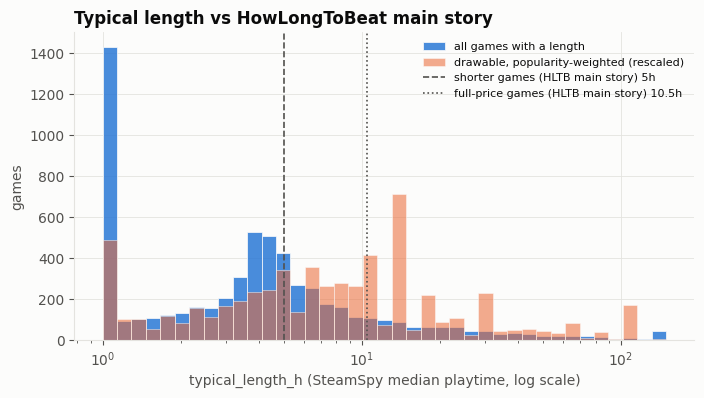

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.logspace(0, np.log10(150), 40)
ax.hist(L_all, bins=bins, color=SERIES[0], alpha=0.85, label="all games with a length", edgecolor=SURFACE, linewidth=0.6)
ax.hist(w_len, bins=bins, color=SERIES[1], alpha=0.55, weights=np.full(len(w_len), len(L_all) / len(w_len)),
        label="drawable, popularity-weighted (rescaled)", edgecolor=SURFACE, linewidth=0.6)
for (lab, v), ls in zip(hltb.items(), ["--", ":"]):
    ax.axvline(v, color=INK2, linestyle=ls, linewidth=1.2, label=lab + f" {v:g}h")
ax.set_xscale("log")
ax.set_xlabel("typical_length_h (SteamSpy median playtime, log scale)")
ax.set_ylabel("games")
ax.set_title("Typical length vs HowLongToBeat main story")
ax.legend(fontsize=8)
save(fig, "01_typical_length")

## 2. Generator v2 rules

Same personas, persona config, mix share, truncated library sizes and per-game hours quantile ranges as v1.
Changes, each with its parameters, reason and source (`archetype_sim_v2.RULES`):

- **A. Real games.** The persona's genre rule picks a genre, its P(online) picks online or offline, and a game is
  drawn from catalogue games with that genre and flag, weighted by Steam 200k players, never twice per library.
  When no game is left, the online flag is relaxed first, then the genre. **Game hours**: a game with ≥ 20 Steam 200k
  players reads its hours off its *own* Steam 200k distribution at the persona's quantile u (capped at its own 99th
  percentile); others use the global distribution.
- **Rule 1, finishing needs hours.** With r = hours ÷ typical length and p the completion propensity:
  P(completed) = p · σ((ln r − ln r₀) / s), with r₀ = √(0.5·1.5) ≈ 0.87 and s = ln 3 / (2 ln 19) ≈ 0.187, so the factor
  is exactly 5% at r = 0.5 and 95% at r = 1.5, symmetric in ln r.
- **Rule 2, trophies follow hours.** Trophies rise linearly to a share **M = 0.6** of the list by the end of the
  main story (r = 1); the remaining 1 − M rises over the extra **E = 2** × length hours, reachable only on completed games,
  times the per-game trophy Beta draw. 100% only when completed and r ≥ 1 + E.
- **Rule 3, multiplayer-only games have no ending.** P(completed) = 0.02.
- **Rule 4, engagement.** z ~ N(0, 1) per player: hours quantile u + 0.05·z, active months + 1·z (both clipped to the
  persona's range), completion and trophy propensities + 0.3·z on the logit scale.
- **Rule 5, trophy hunters.** 10% of players: trophy fraction ≥ a Beta(4,4) draw on every game with a list, never 100%
  on an unfinished game.

Every random number is drawn whichever rules are on (common random numbers), so a §6 variant differs from v2 only
through the rule it changes. In v1 the trophy Beta was already drawn per game, so it stays the trophy propensity.

In [7]:
rules_tab = pd.DataFrame([
    {"rule": k, "parameters": {p: v for p, v in r.items() if p not in ("on", "reason", "source")},
     "reason": r["reason"], "source": r["source"]}
    for k, r in sim2.RULES.items()
]).set_index("rule")
R["rules"] = json.loads(json.dumps(sim2.RULES, default=list))
with pd.option_context("display.max_colwidth", 140):
    display(rules_tab)

,parameters,reason,source
rule,,,
real_games,{'popularity_weight': 'steam200k_players'},"Genres, online flag, list size and length belong to a game, so they are taken from a real one; common games are drawn more often.","Steam Store Games (Kaggle, SteamSpy 2019) + Steam 200k player counts"
game_hours,"{'min_players': 20, 'cap_quantile': 0.99}",Hours depend on the game's length: a game with >= 20 Steam 200k players takes its hours from its own Steam 200k distribution at the pers...,Steam 200k per-game playtime
rule1_finish_needs_hours,"{'r_low': 0.5, 'r_high': 1.5, 'edge': 0.05, 'r_mid': 0.8660254037844386, 'r_scale': 0.1865571500108185}","You can't finish a game without playing it through: P(completed) < 5% of p below half the typical length, >= 95% of p from 1.5x, logisti...","Logic; main-story lengths from HowLongToBeat (Bailey et al., arXiv 2205.15163)"
rule2_trophies_follow_hours,"{'extra_ratio_E': 2.0, 'story_share_M': 0.6}",Trophies rise with hours to a share M of the list by the end of the main story (r = 1); the remaining 1 - M rises over the extra E x len...,"E: Bailey et al.: +8.6h after the main story for shorter games, +23.6h for full-price ones, about 1.7-2.25x the main story -> E = 2. M =..."
rule3_multiplayer_only_no_ending,{'p_completed': 0.02},Live-service games have no ending to reach; 2% allows campaigns the store categories don't show.,Logic
rule4_engagement,"{'hours_quantile_shift': 0.05, 'months_per_z': 1.0, 'logit_shift': 0.3}","Engaged players play more and also pursue more goals, so one hidden z ~ N(0,1) moves hours, active months and both propensities together...",Logic
rule5_trophy_hunters,"{'share': 0.1, 'floor_beta': (4, 4)}","Some players chase trophies on every game: on every game with a list their trophy fraction is at least a Beta(4,4) draw, even unfinished...","Bailey et al.: trophy completion rates are bimodal, easy trophies attributed to players chasing profile scores"


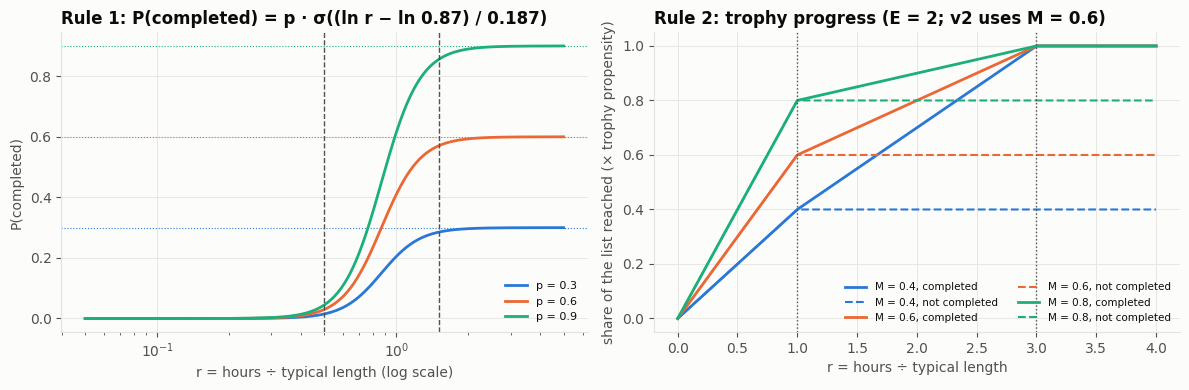

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
rs = np.logspace(np.log10(0.05), np.log10(5), 300)
for p, col in zip([0.3, 0.6, 0.9], SERIES):
    a1.plot(rs, [p * sim2.finish_factor(r) for r in rs], color=col, linewidth=2, label=f"p = {p}")
    a1.axhline(p, color=col, linewidth=0.8, linestyle=":")
for x in (0.5, 1.5):
    a1.axvline(x, color=INK2, linewidth=1, linestyle="--")
a1.set_xscale("log")
a1.set_xlabel("r = hours ÷ typical length (log scale)")
a1.set_ylabel("P(completed)")
a1.set_title("Rule 1: P(completed) = p · σ((ln r − ln 0.87) / 0.187)")
a1.legend(fontsize=8)
rs2 = np.linspace(0, 4, 400)
E = sim2.RULES["rule2_trophies_follow_hours"]["extra_ratio_E"]
for m, col in zip([0.4, 0.6, 0.8], SERIES):
    a2.plot(rs2, [sim2.trophy_progress(r, True, m, E) for r in rs2], color=col, linewidth=2, label=f"M = {m}, completed")
    a2.plot(rs2, [sim2.trophy_progress(r, False, m, E) for r in rs2], color=col, linewidth=1.5, linestyle="--",
            label=f"M = {m}, not completed")
a2.axvline(1, color=INK2, linewidth=1, linestyle=":")
a2.axvline(1 + E, color=INK2, linewidth=1, linestyle=":")
a2.set_xlabel("r = hours ÷ typical length")
a2.set_ylabel("share of the list reached (× trophy propensity)")
a2.set_title(f"Rule 2: trophy progress (E = {E:g}; v2 uses M = 0.6)")
a2.legend(fontsize=7.5, ncol=2)
fig.tight_layout()
save(fig, "02_rules_1_2")

## 3. Plausibility checks (before training)

v1's population is regenerated exactly (`generate_players(version=1)`, seed 42); the check below confirms it still
reproduces the frozen model 1.0.0.

In [9]:
P1 = L.players_v1(cal)
LOG = {}
P2 = L.players_v2(cal, CAT, log=LOG)
v1 = L.train(P1)
m1 = L.MODEL_V1
v1_ok = {
    "k": v1["k"] == m1["k"],
    "scaler": np.allclose(v1["scaler"].mean_, m1["scaler"]["mean"], atol=1e-9)
              and np.allclose(v1["scaler"].scale_, m1["scaler"]["scale"], atol=1e-9),
    "centres": np.allclose(v1["model"].cluster_centers_, [c["centre_scaled"] for c in m1["clusters"]], atol=1e-9),
    "JSON labels": bool((L.V1.assign(v1["raw"]) == v1["model"].labels_).all()),
}
assert all(v1_ok.values()), v1_ok
R["v1_reproduces"] = v1_ok
n_draws = sum(LOG["fallback"])
R["draws"] = {"total": n_draws, "fallback_levels": LOG["fallback"], "hours_source": LOG["hours_source"]}
print("v1 reproduces model 1.0.0:", v1_ok)
print("game draws:", n_draws, "| genre+flag / genre only / flag only / any:", LOG["fallback"])
print("hours from the game's own distribution: {game} ({p:.0%}), global: {global}".format(
    p=LOG["hours_source"]["game"] / n_draws, **LOG["hours_source"]))

v1 reproduces model 1.0.0: {'k': True, 'scaler': True, 'centres': True, 'JSON labels': True}
game draws: 6695 | genre+flag / genre only / flag only / any: [6267, 412, 16, 0]
hours from the game's own distribution: 3761 (56%), global: 2934


In [10]:
checks = L.plausibility(P2, sim2.RULES)
R["plausibility"] = checks.fillna("").to_dict("records")
table(checks.set_index("check"), "plausibility")

,count,out of,note
check,,,
completed with r < 0.3 (all games),2,2111,NaN
of which multiplayer-only (rule 3's flat 2%),2,244,NaN
of which not multiplayer-only (rule 1),0,1867,NaN
100% trophies on an unfinished game,0,3724,NaN
"100% trophies, hunters' unfinished games",0,410,NaN
100% trophies with r < 1 + E (3),0,4011,NaN
completed multiplayer-only games,14,664,rate 2.11% vs 2% (binomial ±2 SE: 0.91%–3.09%)
full sets (100%) overall,2,4628,NaN


In [11]:
# Hard constraints: these must be 0 (or, for multiplayer-only completions, near 2%)
c = checks.set_index("check")["count"]
assert c["  of which not multiplayer-only (rule 1)"] == 0
assert c["100% trophies on an unfinished game"] == 0
assert c["100% trophies with r < 1 + E (3)"] == 0
mp = checks.set_index("check").loc["completed multiplayer-only games"]
mp_rate = mp["count"] / mp["out of"]
assert abs(mp_rate - 0.02) <= 2 * np.sqrt(0.02 * 0.98 / mp["out of"]), mp_rate
print("impossible-combination checks pass")

impossible-combination checks pass


In [12]:
raw1, raw2 = v1["raw"], L.features(P2)
s1, s2 = L.spearman_table(raw1), L.spearman_table(raw2)
pairs = list(zip(*np.triu_indices(len(FN), 1)))
corr = pd.DataFrame([{"pair": f"{FN[i]} ↔ {FN[j]}", "v1": s1.iloc[i, j], "v2": s2.iloc[i, j]} for i, j in pairs]).set_index("pair")
corr["Δ"] = corr["v2"] - corr["v1"]
signs = pd.DataFrame([{"pair": f"{a} ↔ {b}", "expected": "+" if sg > 0 else "−", "v1": s1.loc[a, b], "v2": s2.loc[a, b],
                       "v2 sign as expected": bool(np.sign(s2.loc[a, b]) == sg)} for a, b, sg in L.EXPECTED_SIGNS]).set_index("pair")
R["spearman"] = {"v1": s1.to_dict(), "v2": s2.to_dict()}
R["expected_signs"] = signs.reset_index().to_dict("records")
table(corr, "spearman_v1_v2")
table(signs, "expected_signs")
display(signs.round(3))
corr.round(2)

,expected,v1,v2,v2 sign as expected
pair,,,,
log_hours_per_game ↔ trophy_rate,+,0.298,0.549,True
log_activity ↔ trophy_rate,+,-0.011,0.272,True
completion_rate ↔ trophy_rate,+,0.516,0.555,True
online_share ↔ completion_rate,−,-0.014,0.101,False


,v1,v2,Δ
pair,,,
completion_rate ↔ trophy_rate,0.52,0.56,0.04
completion_rate ↔ genre_diversity,-0.02,0.10,0.12
completion_rate ↔ log_hours_per_game,0.30,0.60,0.30
completion_rate ↔ top_game_share,0.03,-0.06,-0.10
completion_rate ↔ log_activity,0.07,0.29,0.21
completion_rate ↔ online_share,-0.01,0.10,0.12
completion_rate ↔ log_games_played,-0.04,0.02,0.06
trophy_rate ↔ genre_diversity,0.05,0.06,0.01
trophy_rate ↔ log_hours_per_game,0.30,0.55,0.25


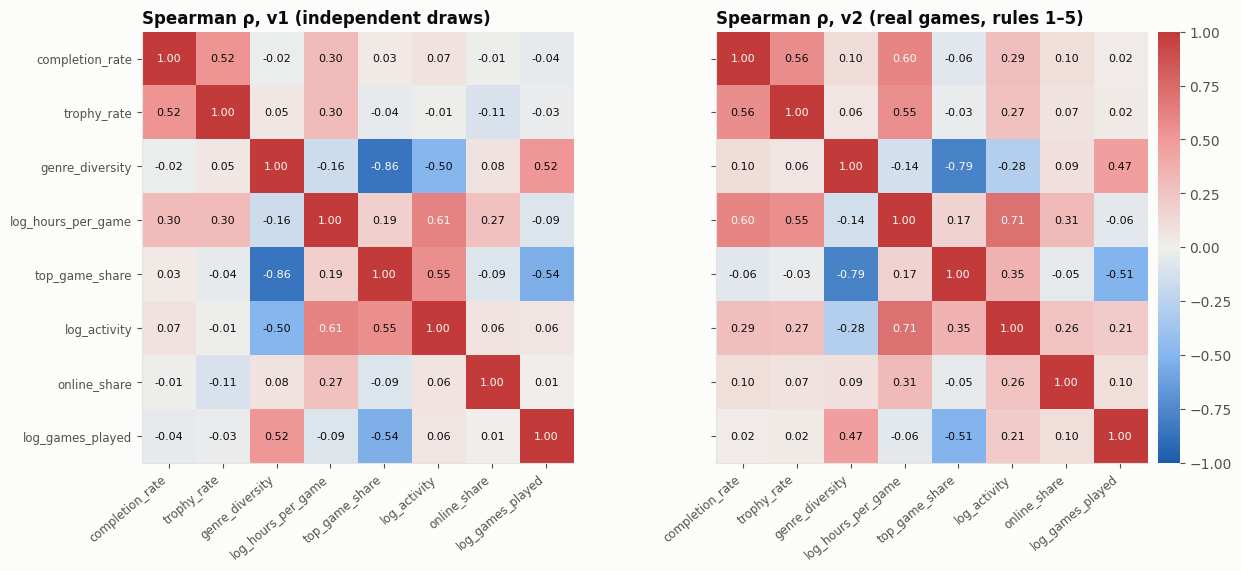

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), sharey=True)
for ax, (title, s) in zip(axes, [("v1 (independent draws)", s1), ("v2 (real games, rules 1–5)", s2)]):
    im = ax.imshow(s.values, cmap=DIVERGING, vmin=-1, vmax=1)
    for i in range(len(FN)):
        for j in range(len(FN)):
            ax.text(j, i, f"{s.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color=SURFACE if abs(s.iloc[i, j]) > 0.6 else INK)
    ax.set_xticks(range(len(FN)), FN, rotation=40, ha="right", fontsize=8.5)
    ax.set_yticks(range(len(FN)), FN, fontsize=8.5)
    ax.set_title(f"Spearman ρ, {title}")
    ax.grid(False)
cb = fig.colorbar(im, ax=axes, fraction=0.02, pad=0.01)
cb.outline.set_visible(False)
save(fig, "03_spearman_v1_v2")

### Online share ↔ completion: the pooled sign

Expected negative, but the pooled correlation is positive. The diagnostics below show why: it is confounded by
per-game hours. Competitors have both the highest online share and the longest per-game hours, and rule 1 lets
long play finish more often, so across personas online share and completion rise together; holding hours per game
fixed, the correlation is negative. No rule was added for online games with a single-player mode.

In [14]:
from scipy.stats import spearmanr
group2 = pd.Series([p["persona"].split(":")[0] for p in P2])
within = {g: float(spearmanr(raw2.loc[i, "online_share"], raw2.loc[i, "completion_rate"]).correlation)
          for g, i in raw2.groupby(group2).groups.items()}
Rk = raw2[["online_share", "completion_rate", "log_hours_per_game"]].rank()
def resid(y, x):
    A = np.c_[np.ones(len(x)), x]
    return y - A @ np.linalg.lstsq(A, y, rcond=None)[0]
partial = float(np.corrcoef(resid(Rk["online_share"], Rk["log_hours_per_game"]),
                            resid(Rk["completion_rate"], Rk["log_hours_per_game"]))[0, 1])
G2 = L.game_table(P2)
G2["kind"] = np.where(G2["_mp_only"], "online, multiplayer-only",
                      np.where(G2["is_online"], "online, has single-player", "offline"))
by_kind = G2.groupby("kind").agg(games=("completed", "size"), completed=("completed", "mean"),
                                 hours_median=("hours", "median"), length_median=("_typical_length_h", "median"),
                                 r_median=("_r", "median"))
persona_means2 = raw2.groupby(group2)[["online_share", "completion_rate", "log_hours_per_game"]].mean()
R["online_completion"] = {"pooled": float(s2.loc["online_share", "completion_rate"]), "partial_given_hours": partial,
                          "within_persona": within, "by_game_kind": by_kind.to_dict("index"),
                          "persona_means": persona_means2.to_dict("index")}
print(f"pooled ρ = {R['online_completion']['pooled']:+.3f}; partial ρ given log_hours_per_game = {partial:+.3f}")
display(pd.Series(within, name="within-persona ρ").round(3).to_frame())
display(by_kind.round(3))
persona_means2.round(3)

pooled ρ = +0.101; partial ρ given log_hours_per_game = -0.110


,within-persona ρ
casual,0.108
competitor,-0.036
completionist,-0.003
devotee,-0.089
explorer,0.081
mixed,0.009


,games,completed,hours_median,length_median,r_median
kind,,,,,
offline,4025,0.207,2.282,3.900,0.587
"online, has single-player",2006,0.242,4.200,6.883,0.700
"online, multiplayer-only",664,0.021,2.905,5.033,0.508


,online_share,completion_rate,log_hours_per_game
casual,0.341,0.066,0.891
competitor,0.803,0.297,2.635
completionist,0.357,0.460,2.115
devotee,0.343,0.096,1.546
explorer,0.356,0.105,1.143
mixed,0.448,0.236,1.734


In [15]:
group1 = v1["group"]
order = sim.PERSONA_NAMES + ["mixed"]
pm = pd.concat({"v1": raw1.groupby(group1)[["completion_rate", "trophy_rate", "log_activity"]].mean(),
                "v2": raw2.groupby(group2)[["completion_rate", "trophy_rate", "log_activity"]].mean()}, axis=1).loc[order]
R["persona_means"] = {f"{a}|{b}": v for (a, b), v in pm.to_dict().items()}
table(pm, "persona_means_v1_v2")
pm.round(3)

v1                                       v2                         
              completion_rate trophy_rate log_activity completion_rate trophy_rate log_activity
completionist           0.785       0.667        2.443           0.460       0.377        2.480
explorer                0.349       0.281        1.711           0.105       0.129        2.042
devotee                 0.444       0.283        3.684           0.096       0.122        3.155
competitor              0.480       0.297        2.950           0.297       0.187        3.204
casual                  0.354       0.282        1.371           0.066       0.088        1.511
mixed                   0.459       0.343        3.177           0.236       0.175        2.765

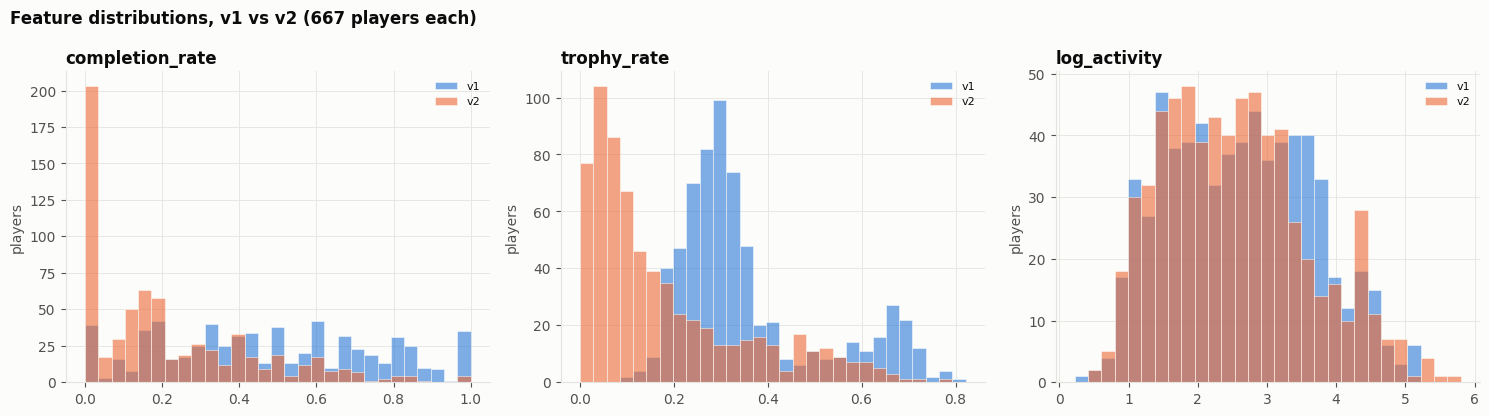

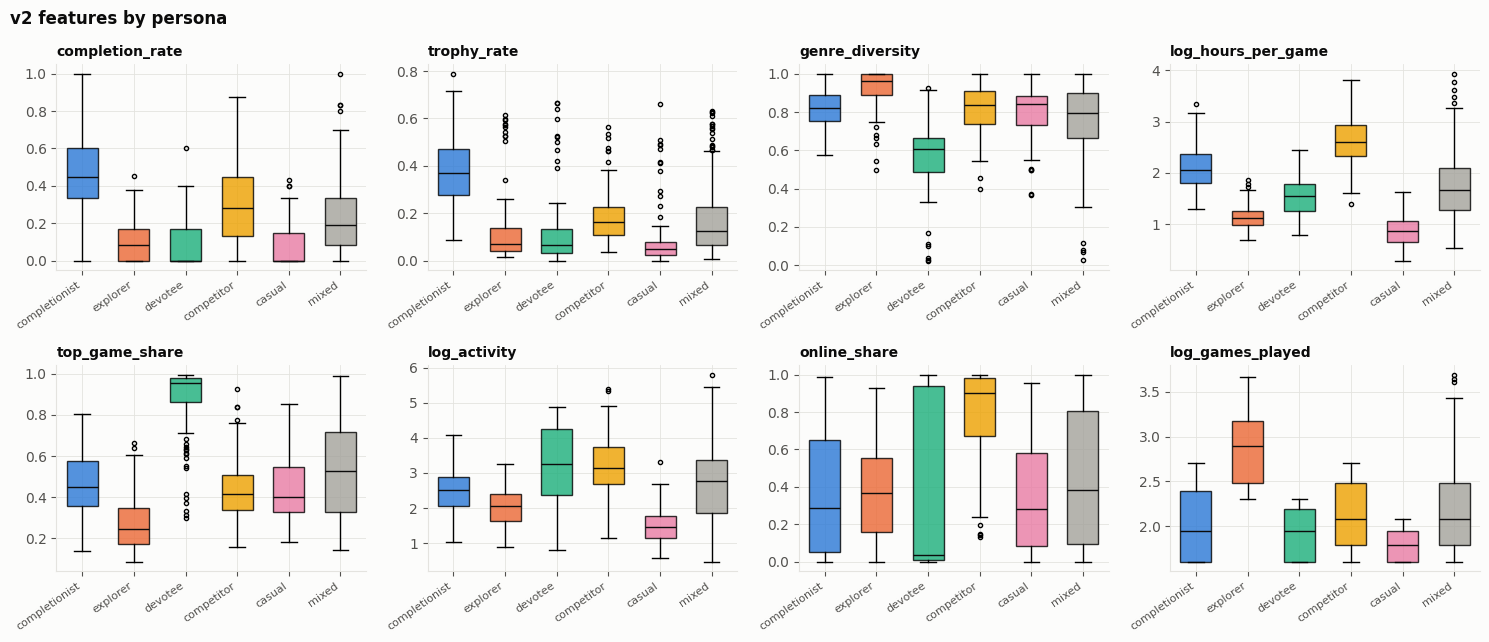

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, f in zip(axes, ["completion_rate", "trophy_rate", "log_activity"]):
    lo, hi = min(raw1[f].min(), raw2[f].min()), max(raw1[f].max(), raw2[f].max())
    bins = np.linspace(lo, hi, 30)
    ax.hist(raw1[f].dropna(), bins=bins, color=V1C, alpha=0.6, label="v1", edgecolor=SURFACE, linewidth=0.6)
    ax.hist(raw2[f].dropna(), bins=bins, color=V2C, alpha=0.6, label="v2", edgecolor=SURFACE, linewidth=0.6)
    ax.set_title(f)
    ax.set_ylabel("players")
    ax.legend(fontsize=8)
fig.suptitle("Feature distributions, v1 vs v2 (667 players each)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "04_distributions_v1_v2")

fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, f in zip(axes.flat, FN):
    data = [raw2.loc[(group2 == g).to_numpy(), f].dropna() for g in order]
    bp = ax.boxplot(data, patch_artist=True, widths=0.6, medianprops={"color": INK}, flierprops={"markersize": 3})
    for patch, g in zip(bp["boxes"], order):
        patch.set_facecolor(PERSONA_COLORS[g]); patch.set_alpha(0.8)
    ax.set_xticks(range(1, len(order) + 1), order, rotation=35, ha="right", fontsize=8)
    ax.set_title(f, fontsize=10)
fig.suptitle("v2 features by persona", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "05_v2_features_by_persona")

## 4. Train v2

v1's pipeline unchanged: training-mean imputation, StandardScaler, k = 2..8 with `KMeans(n_init=20, random_state=42)`,
silhouette + elbow, and the **same pre-registered k rule**: if the best silhouettes are within 0.01, take the largest of
them whose clusters all differ by ≥ 0.5 SD in some feature and each hold ≥ 5% of players; else the highest silhouette.

In [17]:
v2 = L.train(P2)
K2 = v2["k"]
k_table = pd.DataFrame({"silhouette": v2["sil"], "inertia": v2["inertia"]}).rename_axis("k")
R["v2_k"] = {"k": int(K2), "reason": v2["reason"], "silhouette": {int(k): float(s) for k, s in v2["sil"].items()},
             "inertia": {int(k): float(i) for k, i in v2["inertia"].items()},
             "rule_checks": v2["checks"].reset_index().astype(str).to_dict("records")}
print("v2 rule k:", K2, "|", v2["reason"])
display(table(v2["checks"], "v2_k_rule_checks"))
table(k_table, "v2_k_sweep")

v2 rule k: 7 | 2 k within 0.01 -> largest passing k


,silhouette,closest pair,its largest gap (SD),smallest cluster share,(a) gap >= 0.5 SD,(b) share >= 5%,passes
k,,,,,,,
3,0.256051,0-2,1.742508,0.212894,True,True,True
7,0.247279,3-4,1.397902,0.058471,True,True,True


,silhouette,inertia
k,,
2,0.217327,4109.983766
3,0.256051,3220.887601
4,0.243486,2757.893932
5,0.238728,2477.975478
6,0.242559,2277.040162
7,0.247279,2125.665866
8,0.241086,2004.366128


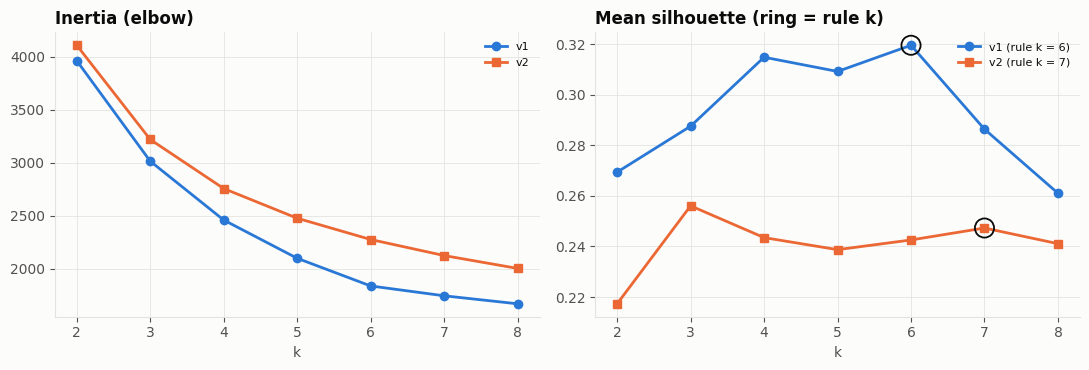

In [18]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.plot(L.KS, [v1["inertia"][k] for k in L.KS], color=V1C, linewidth=2, marker="o", label="v1")
a1.plot(L.KS, k_table["inertia"], color=V2C, linewidth=2, marker="s", label="v2")
a1.set_title("Inertia (elbow)"); a1.set_xlabel("k"); a1.legend(fontsize=8)
a2.plot(L.KS, [v1["sil"][k] for k in L.KS], color=V1C, linewidth=2, marker="o", label=f"v1 (rule k = {v1['k']})")
a2.plot(L.KS, k_table["silhouette"], color=V2C, linewidth=2, marker="s", label=f"v2 (rule k = {K2})")
for run, col in ((v1, V1C), (v2, V2C)):
    a2.scatter([run["k"]], [run["sil"][run["k"]]], s=190, facecolor="none", edgecolor=INK, linewidth=1.3, zorder=4)
a2.set_title("Mean silhouette (ring = rule k)"); a2.set_xlabel("k"); a2.legend(fontsize=8)
for a in (a1, a2):
    a.set_xticks(L.KS)
fig.tight_layout()
save(fig, "06_choose_k")

In [19]:
stab = L.stability(v2)
p_ari = L.persona_ari(v2)
R["v2_stability"] = stab
R["v2_persona_ari"] = p_ari
R["v1_reference"] = {"stability": m1["training"]["stability_mean_pairwise_ari"], "persona_ari": m1["training"]["persona_sanity_ari"],
                     "silhouette": m1["silhouette"]}
print(f"stability, 10 KMeans seeds: mean pairwise ARI {stab['mean_pairwise']:.3f} (min {stab['min_pairwise']:.3f})  | v1 {m1['training']['stability_mean_pairwise_ari']}")
print(f"persona sanity ARI (pure players): {p_ari:.3f}  | v1 {m1['training']['persona_sanity_ari']}")

stability, 10 KMeans seeds: mean pairwise ARI 0.922 (min 0.766)  | v1 1.0
persona sanity ARI (pure players): 0.466  | v1 0.8453


### Centres in original units, and suggested names

Clusters are **not named** here. *Suggested* is the pure persona whose average is nearest the centre (v1 cell 33);
*nearest v1 archetype* is the Hungarian match of centres in v1's SD units (§5).

In [20]:
model2 = v2["model"]
A2 = L.Assigner.from_run(v2)
v1_names = dict(enumerate(L.V1_NAMES))
cmp12 = L.compare(L.V1, v1_names, A2, {"v1 players": raw1, "v2 players": raw2}, "v2")
suggested, persona_dist = L.suggested_names(v2)
centres2 = pd.DataFrame(A2.centres_original(), columns=FN).rename_axis("cluster")
centres2["players"] = np.bincount(model2.labels_, minlength=K2)
centres2["suggested (nearest persona)"] = suggested
centres2["nearest v1 archetype"] = [cmp12["other_name"][c] for c in range(K2)]
R["v2_centres"] = centres2.reset_index().to_dict("records")
display(table(persona_dist, "v2_persona_distance"))
table(centres2, "v2_centres")

,completionist,explorer,devotee,competitor,casual
cluster,,,,,
0,3.065272,2.275277,2.789684,3.287865,0.398675
1,3.935848,4.552539,1.802665,3.022678,3.765464
2,3.586865,4.326111,1.021487,3.677180,3.466041
3,2.102637,3.248673,3.316745,0.364479,3.602131
4,0.535947,3.737738,3.550483,2.276287,3.652105
5,2.251690,2.992585,3.447478,3.423682,2.671427
6,3.364965,0.534223,4.059088,3.288929,2.937006


,completion_rate,trophy_rate,genre_diversity,log_hours_per_game,top_game_share,log_activity,online_share,log_games_played,players,suggested (nearest persona),nearest v1 archetype
cluster,,,,,,,,,,,
0,0.085271,0.068300,0.808680,1.072939,0.455693,1.502823,0.331837,1.915219,182,casual,Casual
1,0.093282,0.095738,0.524026,1.748347,0.900096,3.635365,0.954182,1.911179,53,devotee,The Main
2,0.138039,0.109214,0.502821,1.710855,0.902771,3.537661,0.037464,1.937919,76,devotee,Devotee
3,0.323534,0.201620,0.832187,2.547788,0.430034,3.308689,0.824476,2.253645,120,competitor,Competitor
4,0.550398,0.387146,0.814829,2.291936,0.483849,2.653061,0.322620,1.968525,98,completionist,Completionist
5,0.108985,0.511334,0.816603,1.272352,0.475886,1.805244,0.328701,2.076148,39,completionist,unmatched v2 cluster 5
6,0.141220,0.116136,0.947315,1.258920,0.249676,2.408041,0.379630,3.031485,99,explorer,Explorer


In [21]:
composition = pd.crosstab(v2["group"], pd.Series(model2.labels_, name="cluster")).loc[order]
R["v2_composition"] = composition.to_dict()
table(composition, "v2_composition")

cluster,0,1,2,3,4,5,6
group,,,,,,,
completionist,8,0,1,13,67,8,3
explorer,22,1,0,2,0,7,68
devotee,17,29,47,0,1,6,0
competitor,7,6,1,77,7,1,1
casual,85,4,2,0,1,8,0
mixed,43,13,25,28,22,9,27


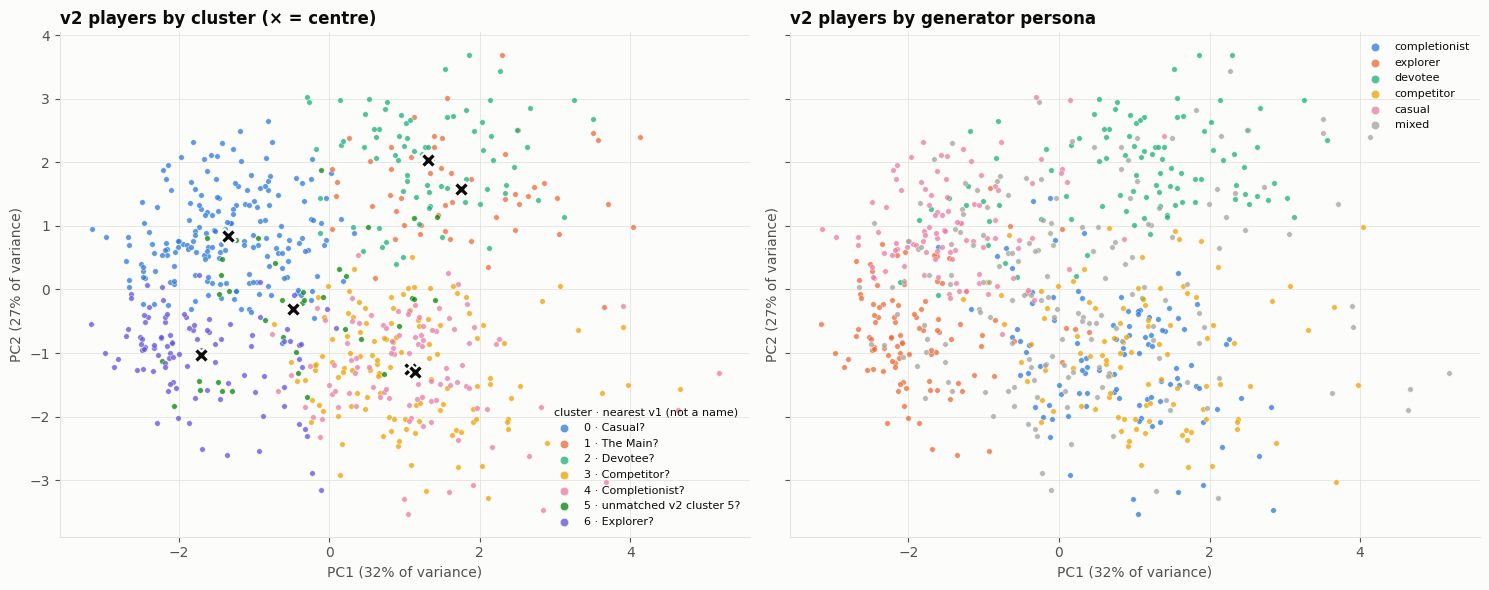

In [22]:
pca = PCA(n_components=2, random_state=SEED).fit(v2["Z"])
P2d = pca.transform(v2["Z"]); C2d = pca.transform(model2.cluster_centers_); ev = pca.explained_variance_ratio_
label = {c: f"{c} · {centres2.loc[c, 'nearest v1 archetype']}?" for c in range(K2)}
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
for c in range(K2):
    m = model2.labels_ == c
    axes[0].scatter(P2d[m, 0], P2d[m, 1], s=16, color=SERIES[c], alpha=0.75, edgecolor=SURFACE, linewidth=0.4, label=label[c])
axes[0].scatter(C2d[:, 0], C2d[:, 1], s=120, color=INK, marker="X", edgecolor=SURFACE, linewidth=1.5, zorder=3)
axes[0].legend(fontsize=8, markerscale=1.5, title="cluster · nearest v1 (not a name)", title_fontsize=8)
axes[0].set_title("v2 players by cluster (× = centre)")
for g in order:
    m = (v2["group"] == g).to_numpy()
    axes[1].scatter(P2d[m, 0], P2d[m, 1], s=16, color=PERSONA_COLORS[g], alpha=0.75, edgecolor=SURFACE, linewidth=0.4, label=g)
axes[1].legend(fontsize=8, markerscale=1.5)
axes[1].set_title("v2 players by generator persona")
for a in axes:
    a.set_xlabel(f"PC1 ({ev[0]:.0%} of variance)"); a.set_ylabel(f"PC2 ({ev[1]:.0%} of variance)")
fig.tight_layout()
save(fig, "07_pca_v2")

### Export the candidate model

Same JSON structure as v1, version `2.0.0-candidate`, written to `models/archetype_model_v2.json`. Names are
placeholders (`v2 cluster N`); the temperature is v1's 0.75 copied as a placeholder. **Neither has been reviewed and
the app does not load this file.**

In [23]:
MODEL_V2_PATH = REPO_DIR / "models" / "archetype_model_v2.json"
names2 = {c: f"v2 cluster {c}" for c in range(K2)}
desc2 = {c: f"Unnamed candidate cluster. Suggested persona: {suggested[c]}; nearest v1 archetype: "
            f"{centres2.loc[c, 'nearest v1 archetype']}." for c in range(K2)}
export = L.export_model(v2, names2, desc2, "2.0.0-candidate", MODEL_V2_PATH, stab, p_ari, extra_training={
    "generator": "archetype_sim_v2 (real Steam store games, rules 1-5; see the model card's Simulation rules)",
    "catalogue": "Kaggle Steam Store Games (SteamSpy 2019) matched to Steam 200k",
    "status": "candidate: not wired into the app; cluster names and temperature not reviewed",
})
saved = json.loads(MODEL_V2_PATH.read_text())
A2j = L.Assigner.from_json(saved)
assert (A2j.assign(raw2) == model2.labels_).all(), "JSON round trip failed"
print("wrote", MODEL_V2_PATH.relative_to(REPO_DIR), "| round trip OK")

wrote models/archetype_model_v2.json | round trip OK


## 5. v1 vs v2

The robustness check's method: v2's clusters are matched to v1's by centre distance (Hungarian, in v1's SD units);
both models assign the same players (v1's 667 and v2's 667); ARI and % reassigned between them. The seed-noise
reference is v2 regenerated with 5 other generator seeds (0–4), each fitted at v2's k and compared with seed 42.

In [24]:
R["v1_vs_v2"] = {
    "k": {"v1": int(m1["k"]), "v2": int(K2)},
    "match_distance_v1_sd": cmp12["dist"],
    "v2_name_by_match": {int(k): v for k, v in cmp12["other_name"].items()},
    "pops": {p: {"ari": d["ari"], "changed": d["changed"]} for p, d in cmp12["pops"].items()},
}
for p, d in cmp12["pops"].items():
    print(f"{p}: ARI {d['ari']:.3f}, reassigned {d['changed']:.1%}")
    table(d["moves"], f"moves_v1_v2_{p.replace(' ', '_')}")
    display(d["moves"])

v1 players: ARI 0.561, reassigned 22.0%


v2,Casual,Competitor,Completionist,Devotee,Explorer,The Main,unmatched v2 cluster 5
reference,,,,,,,
Casual,65,1,35,0,1,0,36
Competitor,1,82,38,1,0,0,0
Completionist,0,0,124,0,0,0,4
Devotee,0,0,11,99,0,0,0
Explorer,0,2,8,0,94,0,2
The Main,0,1,6,0,0,56,0


v2 players: ARI 0.648, reassigned 19.9%


v2,Casual,Competitor,Completionist,Devotee,Explorer,The Main,unmatched v2 cluster 5
reference,,,,,,,
Casual,167,0,15,4,0,2,20
Competitor,4,118,39,0,0,2,2
Completionist,0,0,29,0,0,0,4
Devotee,0,0,6,72,0,0,2
Explorer,11,2,8,0,99,0,9
The Main,0,0,1,0,0,49,2


In [25]:
c1 = L.V1.centres_original()
rows = []
for i, name in v1_names.items():
    j = cmp12["mapping"].get(i)
    for fi, f in enumerate(FN):
        row = {"v1 archetype": name, "feature": f, "v1": c1[i, fi]}
        if j is not None:
            row["v2 cluster"] = j
            row["v2"] = A2.centres_original()[j, fi]
            row["Δ"] = row["v2"] - row["v1"]
            row["Δ (v1 SD)"] = row["Δ"] / L.V1.scale[fi]
        rows.append(row)
cent = pd.DataFrame(rows)
cent["v1 archetype"] = pd.Categorical(cent["v1 archetype"], L.NAME_ORDER, ordered=True)
cent = cent.sort_values(["v1 archetype", "feature"], key=lambda s: s if s.name == "v1 archetype" else s.map(FN.index))
R["centres_v1_v2"] = cent.astype({"v1 archetype": str}).to_dict("records")
table(cent.set_index(["v1 archetype", "feature"]), "centres_v1_v2")
cent.pivot(index="v1 archetype", columns="feature", values="Δ (v1 SD)")[FN].round(2)

feature,completion_rate,trophy_rate,genre_diversity,log_hours_per_game,top_game_share,log_activity,online_share,log_games_played
v1 archetype,,,,,,,,
Completionist,-0.84,-1.57,0.06,0.37,0.27,0.21,0.14,-0.35
Explorer,-0.77,-1.06,-0.09,0.18,0.24,0.40,0.16,0.19
Devotee,-1.00,-1.18,0.63,-0.06,-0.13,-0.26,0.04,-0.09
The Main,-1.31,-1.24,0.77,0.06,-0.07,-0.09,-0.02,-0.19
Competitor,-0.51,-0.64,0.13,-0.14,0.15,0.24,0.10,0.27
Casual,-1.03,-1.40,0.09,0.19,0.31,0.08,0.02,0.13


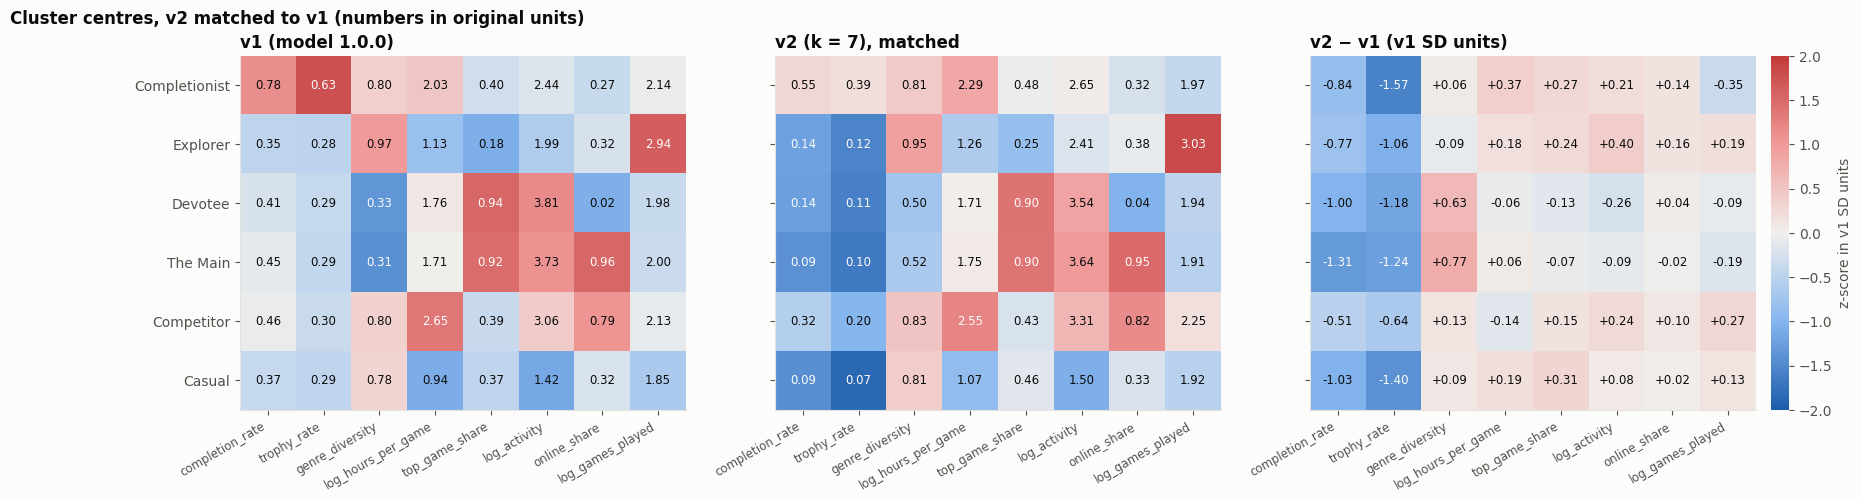

In [26]:
row_ids = [L.V1_NAMES.index(n) for n in L.NAME_ORDER]
v2_rows = [cmp12["mapping"].get(i) for i in row_ids]
panels = [("v1 (model 1.0.0)", c1[row_ids])]
v2vals = np.array([A2.centres_original()[j] if j is not None else np.full(len(FN), np.nan) for j in v2_rows])
panels.append((f"v2 (k = {K2}), matched", v2vals))
fig, axes = plt.subplots(1, 3, figsize=(20, 4.6), sharey=True)
lim = 2.0
for ax, (title, vals) in zip(axes[:2], panels):
    z = (vals - L.V1.mean) / L.V1.scale
    im = ax.imshow(z, cmap=DIVERGING, vmin=-lim, vmax=lim, aspect="auto")
    for i in range(len(row_ids)):
        for j in range(len(FN)):
            if not np.isnan(vals[i, j]):
                ax.text(j, i, f"{vals[i, j]:.2f}", ha="center", va="center", fontsize=8.5,
                        color=SURFACE if abs(z[i, j]) > 0.6 * lim else INK)
    ax.set_xticks(range(len(FN)), FN, rotation=30, ha="right", fontsize=8.5); ax.set_title(title); ax.grid(False)
d = (v2vals - panels[0][1]) / L.V1.scale
ax = axes[2]
ax.imshow(d, cmap=DIVERGING, vmin=-lim, vmax=lim, aspect="auto")
for i in range(len(row_ids)):
    for j in range(len(FN)):
        if not np.isnan(d[i, j]):
            ax.text(j, i, f"{d[i, j]:+.2f}", ha="center", va="center", fontsize=8.5, color=SURFACE if abs(d[i, j]) > 0.6 * lim else INK)
ax.set_xticks(range(len(FN)), FN, rotation=30, ha="right", fontsize=8.5); ax.set_title("v2 − v1 (v1 SD units)"); ax.grid(False)
axes[0].set_yticks(range(len(row_ids)), L.NAME_ORDER)
cb = fig.colorbar(im, ax=axes, fraction=0.012, pad=0.01); cb.set_label("z-score in v1 SD units", color=INK2); cb.outline.set_visible(False)
fig.suptitle("Cluster centres, v2 matched to v1 (numbers in original units)", x=0.01, ha="left", fontweight="bold")
save(fig, "08_centres_v1_v2")

In [27]:
def at_k(run, k):
    """The run's model at k (from its sweep), as an Assigner."""
    return L.Assigner.from_run(run, run["fits"][k])

ref2_names = {c: f"c{c}" for c in range(K2)}
noise_runs = {s: L.train(L.players_v2(cal, CAT, seed=s)) for s in L.NOISE_SEEDS}
noise = {}
for s, run in noise_runs.items():
    res = L.compare(A2, ref2_names, at_k(run, K2), {"v2 seed-42 players": raw2, f"seed {s} players": run["raw"]}, f"seed {s}")
    noise[s] = {"rule_k": int(run["k"]), "pops": {p: {"ari": d["ari"], "changed": d["changed"]} for p, d in res["pops"].items()}}
noise_ari = [d["ari"] for n in noise.values() for d in n["pops"].values()]
noise_chg = [d["changed"] for n in noise.values() for d in n["pops"].values()]
NOISE_MIN = min(noise_ari)
R["v2_seed_noise"] = {"runs": noise, "ari_range": [min(noise_ari), max(noise_ari)],
                      "changed_range": [min(noise_chg), max(noise_chg)]}
print("v2 rule k on seeds 0-4:", {s: n["rule_k"] for s, n in noise.items()})
print(f"seed-noise ARI {min(noise_ari):.3f}–{max(noise_ari):.3f}, reassigned {min(noise_chg):.1%}–{max(noise_chg):.1%}")

v2 rule k on seeds 0-4: {0: 3, 1: 3, 2: 7, 3: 6, 4: 3}
seed-noise ARI 0.636–0.869, reassigned 6.7%–23.7%


### Real users

Assigned with both models by `notebooks/sim_v2_real_users.py`, run locally with database access (read-only
session; users with ≥ 5 manual-log games, the endpoint's own data path). The table is anonymised.

In [28]:
real_path = RESULTS / "real_users.csv"
if real_path.exists():
    real = pd.read_csv(real_path)
    R["real_users"] = {"n": len(real), "changed": int(real["changed"].sum()), "rows": real.to_dict("records")}
    display(real)
else:
    print("no real_users.csv yet: run notebooks/sim_v2_real_users.py locally")

,user,games,v1 archetype,v1 %,v2 cluster,v2 cluster ≈ v1,v2 %,changed
0,user 1,12,Competitor,48,v2 cluster 3,Competitor,39,False
1,user 2,12,Completionist,49,v2 cluster 4,Completionist,52,False
2,user 3,9,Competitor,57,v2 cluster 3,Competitor,48,False
3,user 4,10,Competitor,64,v2 cluster 3,Competitor,47,False
4,user 5,5,Completionist,64,v2 cluster 4,Completionist,68,False


## 6. Sensitivity of the new rules

Each variant changes one design guess, regenerates the seed-42 population, re-runs the k sweep and the k rule, fits
the model at v2's k and compares it with v2 on both populations. Verdict rule from the robustness check:
**Substantial effect** if the rule's k differs from v2's or the lower ARI < 0.8; **No meaningful effect** if the lower
ARI is within the seed-noise range; else **Small effect**.

In [29]:
r4 = sim2.RULES["rule4_engagement"]
def eng(f):
    return {"hours_quantile_shift": r4["hours_quantile_shift"] * f, "months_per_z": r4["months_per_z"] * f,
            "logit_shift": r4["logit_shift"] * f}
VARIANTS = {
    "rule 1 off (no hours needed to finish)": dict(rule1_finish_needs_hours={"on": False}),
    "rule 2 off (v1 trophies)": dict(rule2_trophies_follow_hours={"on": False}),
    "rule 3 off (multiplayer-only can finish)": dict(rule3_multiplayer_only_no_ending={"on": False}),
    "rule 4 off (no engagement)": dict(rule4_engagement={"on": False}),
    "rule 5 off (no trophy hunters)": dict(rule5_trophy_hunters={"on": False}),
    "engagement × 0.5": dict(rule4_engagement=eng(0.5)),
    "engagement × 1.5": dict(rule4_engagement=eng(1.5)),
    "E = 1.5": dict(rule2_trophies_follow_hours={"extra_ratio_E": 1.5}),
    "E = 2.5": dict(rule2_trophies_follow_hours={"extra_ratio_E": 2.5}),
    "M = 0.4": dict(rule2_trophies_follow_hours={"story_share_M": 0.4}),
    "M = 0.8": dict(rule2_trophies_follow_hours={"story_share_M": 0.8}),
    "hunters 5%": dict(rule5_trophy_hunters={"share": 0.05}),
    "hunters 20%": dict(rule5_trophy_hunters={"share": 0.20}),
}
sens = []
for name, change in VARIANTS.items():
    run = L.train(L.players_v2(cal, CAT, rules=sim2.rules_variant(**change)))
    res = L.compare(A2, ref2_names, at_k(run, K2), {"v2 players": raw2, "variant players": run["raw"]}, "variant")
    a = {p: d["ari"] for p, d in res["pops"].items()}
    ch = {p: d["changed"] for p, d in res["pops"].items()}
    sens.append({"variant": name, "rule k": int(run["k"]), "ARI (v2 players)": a["v2 players"],
                 "ARI (variant players)": a["variant players"], "% reassigned (v2 players)": 100 * ch["v2 players"],
                 "% reassigned (variant players)": 100 * ch["variant players"],
                 "max centre shift (v2 SD)": max(res["dist"].values()),
                 "verdict": L.verdict(run["k"] == K2, min(a.values()), NOISE_MIN),
                 # Supplementary, not the pre-registered verdict: v2's own seed noise already changes the
                 # rule's k and has ARI < 0.8, so this column compares the ARI with the noise range only
                 "ARI vs seed noise (supplementary)": "below noise range" if min(a.values()) < NOISE_MIN
                                                      else "within/above noise range"})
sens = pd.DataFrame(sens).set_index("variant")
noise_row = {"rule k": "/".join(str(n["rule_k"]) for n in noise.values()),
             "ARI (v2 players)": f"{min(noise_ari):.3f}–{max(noise_ari):.3f}", "% reassigned (v2 players)":
             f"{100*min(noise_chg):.1f}–{100*max(noise_chg):.1f}"}
R["sensitivity"] = sens.reset_index().to_dict("records")
R["sensitivity_noise_row"] = noise_row
print(f"v2: k = {K2}; seed noise (5 generator seeds): ARI {noise_row['ARI (v2 players)']}, reassigned {noise_row['% reassigned (v2 players)']}%")
table(sens, "sensitivity", 3)

v2: k = 7; seed noise (5 generator seeds): ARI 0.636–0.869, reassigned 6.7–23.7%


,rule k,ARI (v2 players),ARI (variant players),% reassigned (v2 players),% reassigned (variant players),max centre shift (v2 SD),verdict,ARI vs seed noise (supplementary)
variant,,,,,,,,
rule 1 off (no hours needed to finish),6,0.790665,0.634617,12.293853,21.739130,3.352736,Substantial effect,below noise range
rule 2 off (v1 trophies),6,0.708993,0.560090,24.887556,34.332834,2.172925,Substantial effect,below noise range
rule 3 off (multiplayer-only can finish),3,0.878685,0.889579,6.146927,5.697151,0.471810,Substantial effect,within/above noise range
rule 4 off (no engagement),7,0.835611,0.799743,7.346327,9.295352,0.794172,Substantial effect,within/above noise range
rule 5 off (no trophy hunters),3,0.756088,0.814393,24.587706,20.839580,2.987002,Substantial effect,within/above noise range
engagement × 0.5,8,0.813140,0.826023,8.695652,8.095952,0.755449,Substantial effect,within/above noise range
engagement × 1.5,6,0.698653,0.662736,18.440780,22.038981,2.946953,Substantial effect,within/above noise range
E = 1.5,3,0.775113,0.770800,16.191904,16.341829,1.446160,Substantial effect,within/above noise range
E = 2.5,7,1.000000,1.000000,0.000000,0.000000,0.037271,No meaningful effect,within/above noise range


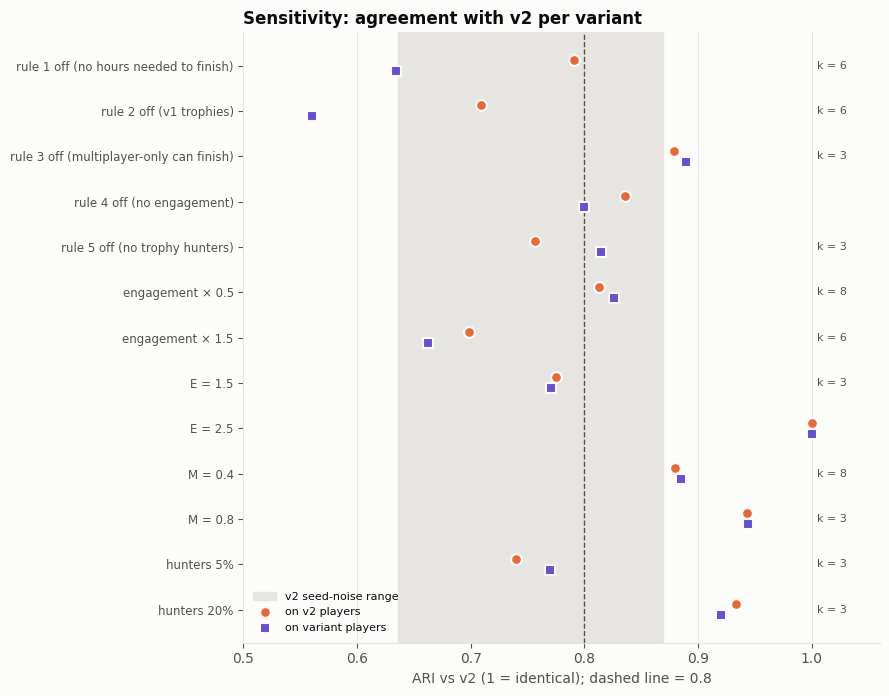

In [30]:
fig, ax = plt.subplots(figsize=(9, 0.42 * len(sens) + 1.6))
y = np.arange(len(sens))
ax.axvspan(min(noise_ari), max(noise_ari), color=GRID, alpha=0.9, zorder=0, label="v2 seed-noise range")
ax.axvline(0.8, color=INK2, linestyle="--", linewidth=1)
ax.scatter(sens["ARI (v2 players)"], y - 0.12, s=60, marker="o", color=V2C, edgecolor=SURFACE, linewidth=1.5, label="on v2 players", zorder=3)
ax.scatter(sens["ARI (variant players)"], y + 0.12, s=60, marker="s", color=SERIES[6], edgecolor=SURFACE, linewidth=1.5, label="on variant players", zorder=3)
for yi, (name, r) in enumerate(sens.iterrows()):
    if r["rule k"] != K2:
        ax.text(1.005, yi, f"k = {r['rule k']}", va="center", fontsize=8, color=INK2)
ax.set_yticks(y, sens.index, fontsize=8.5)
ax.invert_yaxis()
ax.set_xlim(min(0.5, sens[["ARI (v2 players)", "ARI (variant players)"]].min().min() - 0.05), 1.06)
ax.set_xlabel("ARI vs v2 (1 = identical); dashed line = 0.8")
ax.set_title("Sensitivity: agreement with v2 per variant")
ax.legend(loc="lower left", fontsize=8)
ax.grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "09_sensitivity")

In [31]:
(RESULTS / "results.json").write_text(json.dumps(R, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)) + "\n")
print("wrote", (RESULTS / "results.json").relative_to(REPO_DIR))

wrote notebooks/sim_v2/results.json
